# Identifikasi Tanaman TOGA Pakai Gambar Daun dengan MobileNetV2

Di notebook ini, kita bakal bikin sebuah program AI untuk mengelompokkan 10 jenis tanaman TOGA (tanaman herbal) hanya dari fotonya saja. Model AI ini dibuat pakai pondasi **MobileNetV2 **. Selain itu, kita juga pasang fitur **Early Stopping** pas AI-nya lagi dilatih, biar proses blajarnya berhenti otomatis kalau udah dapet hasil yang paling mantap.

Garis besar langkahnya gini:
1. Siapin data gambar daun dari folder `dataset`
2. Cek apakah ada foto yang rusak, lalu bagi datanya jadi porsi buat belajar, latihan, dan ujian (tanpa perlu bikin folder baru secara manual dan ribet).
3. "Ngemodif" foto-fotonya sedikit kayak diputar atau digeser (Augmentasi) biar AI-nya makin pinter.
4. Latih AI-nya pake model MobileNetV2 sekalian aktifkan *Early Stopping*.
5. Kalo udah pinter, simpan "otak" AI-nya ke bentuk `.keras`, `.h5`, dan `SavedModel`.

## 1. Import Paket-paket Penting (Library)

Di langkah pertama ini, kita masukin alat-alat (library) yang bakal ngebantu banget waktu bikin si AI:
- **`os` & `PIL (Pillow)`**: Buat bantu kita ngobrak-ngabrik direktori/folder gambar di laptop. Terus si PIL itu bantu nampilin gambar tanpa error (biar sistem nggak marah kalo nemu foto macet atau *Truncated*).
- **`pandas`, `numpy`**: Tukang angkut data kita. Mereka ngeberesin tumpukan lokasi *file* foto jadi berbentuk tabel Excel yang rapi.
- **`matplotlib.pyplot`, `seaborn`**: Ini bagian senimannya. Buat bikin grafik dan liat sebaran gambar yang kita punya lebih enak.
- **`tensorflow`, `keras`**: Jantung utama pembuat *"Robot AI"* atau Otaknya (*Deep Learning*). Nanti kita bakal pake alat-alat bawaan Keras (contohnya `ImageDataGenerator` yang kayak "pabrik" untuk bikin editan gambar massal di RAM).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, Input, MaxPooling2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

ImageFile.LOAD_TRUNCATED_IMAGES = True

## 2. Ambil Dataset dan Ingat Lokasi Fotonya (Baca Path)

Di kotak kode ini, kita pake trik **"Males Mindahin File Jadi Folder"** alias **"No-Folder-Split"**. Jadinya, nggak usah repot pindahin gambar ke folder terpisah kayak Train, Val, sama Test (karena itu bikin pegel).

1. **Aturan Pembagian**: `80%` buat Belajar (Train), `10%` buat Latihan Ujian (Validation), dan `10%` buat Ujian Akhir (Test). Kalo dijumlah total jadi 100%.
2. **Razia Folder**: Algoritmanya ngepoin satu-satu isi folder kita dan cuma ambil gambar yang beneran (yang formatnya cuman `.jpg`, `.png`, `.jpeg`).
3. **Simpen ke Tabel**: Semua alamat lokasi gambarnya disimpen ke tabel ingetan (pakai `DataFrame / all_data_df`), lengkap sama jawaban namanya (misal nama Daun Sirih). Kita bisa tau jumlah fotonya berapa sekarang.

In [2]:
# Path dataset dan parameter split (tanpa membuat folder baru)
dataset_dir = "/kaggle/input/datasets/ilhamibnuahmad/dataset-tanaman-herbal/tanaman herbal"
train_ratio = 0.8
val_ratio = 0.1
test_ratio = 0.1
random_state = 42

assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-9, "Rasio split harus berjumlah 1.0"

image_extensions = (".png", ".jpg", ".jpeg")
records = []

for class_name in sorted(os.listdir(dataset_dir)):
    class_path = os.path.join(dataset_dir, class_name)
    if not os.path.isdir(class_path):
        continue
    for file_name in os.listdir(class_path):
        if file_name.lower().endswith(image_extensions):
            records.append(
                {
                    "filepath": os.path.join(class_path, file_name),
                    "label": class_name,
                }
            )

all_data_df = pd.DataFrame(records)
print(f"Total gambar ditemukan: {len(all_data_df)}")
print(f"Jumlah kelas: {all_data_df['label'].nunique()}")

Total gambar ditemukan: 4545
Jumlah kelas: 13


## 3. Beresin Foto Rusak & Bagi Data Biar Adil (Stratified Data Split)

Pernah nerima foto WA yang rusak pas didownload? AI juga benci sama foto rusak! Jadi bagian ini tugasnya ngebuang foto *zonk*:

1. **Buang Foto Rusak**: Bikin tukang sapu pakai punggawa `is_valid_image`. Kalau foto itu eror atau kosong, nggak bakal dipakai belajar, biar AI-nya nggak *"Error / Crash"*.
2. **Karantina**: Data buangan masuk ke `corrupted_df`. Sisanya lanjut pelatihan.
3. **Bagi Rata (Adil)**: Ini fitur gokil pake `stratify` dari _sklearn_. Kenapa? Supaya kalau nanti dibikin proporsi 80:10:10, di partisi 10% ada *kemangi* dapet 5, daun *salam* 5, daun *sirih* 5. Jadinya nggak berat sebelah (contohnya Train isinya salam semua, itu gak boleh). Ini biar model kita adil dari awal dan **nggak buta varietas**.

In [3]:
def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

all_data_df["is_valid"] = all_data_df["filepath"].apply(is_valid_image)
clean_df = all_data_df[all_data_df["is_valid"]].drop(columns=["is_valid"]).reset_index(drop=True)
corrupted_df = all_data_df[~all_data_df["is_valid"]].reset_index(drop=True)

print(f"Gambar valid: {len(clean_df)}")
print(f"Gambar rusak: {len(corrupted_df)}")
if len(corrupted_df) > 0:
    print("Contoh gambar rusak:")
    print(corrupted_df["filepath"].head())

def safe_stratified_split(df, test_size, seed):
    min_count = df["label"].value_counts().min()
    stratify_col = df["label"] if min_count >= 2 else None
    return train_test_split(df, test_size=test_size, random_state=seed, stratify=stratify_col)

train_df, temp_df = safe_stratified_split(clean_df, test_size=(1 - train_ratio), seed=random_state)
val_df, test_df = safe_stratified_split(
    temp_df,
    test_size=(test_ratio / (val_ratio + test_ratio)),
    seed=random_state,
 )

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

class_names = sorted(clean_df["label"].unique())

print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")

Gambar valid: 4545
Gambar rusak: 0
Train: 3636
Validation: 454
Test: 455


## 4. Ngintip Jumlah Data Aslinya (Distribusi Original)

Sebelum masuk ngajarin si AI capek-capek, cek dulu daun mana yang paling banyak disumbang ke komputer? Ini jangan sampe berat sebelah (_imbalance_) parah.

- Baris ini pake _Seaborn_ `sns.barplot` (buat bikin grafik batang melintang segede layar).
- Ngeliat grafik sebelum dipecah bantu kita ngeyakinin bahwa model si AI nggak bakal "nyontek" buat suka nebak satu Daun doang yang fotonya segunung. Hasil AI yang cerdas datang dari data yang porsinya nggak jomplang.

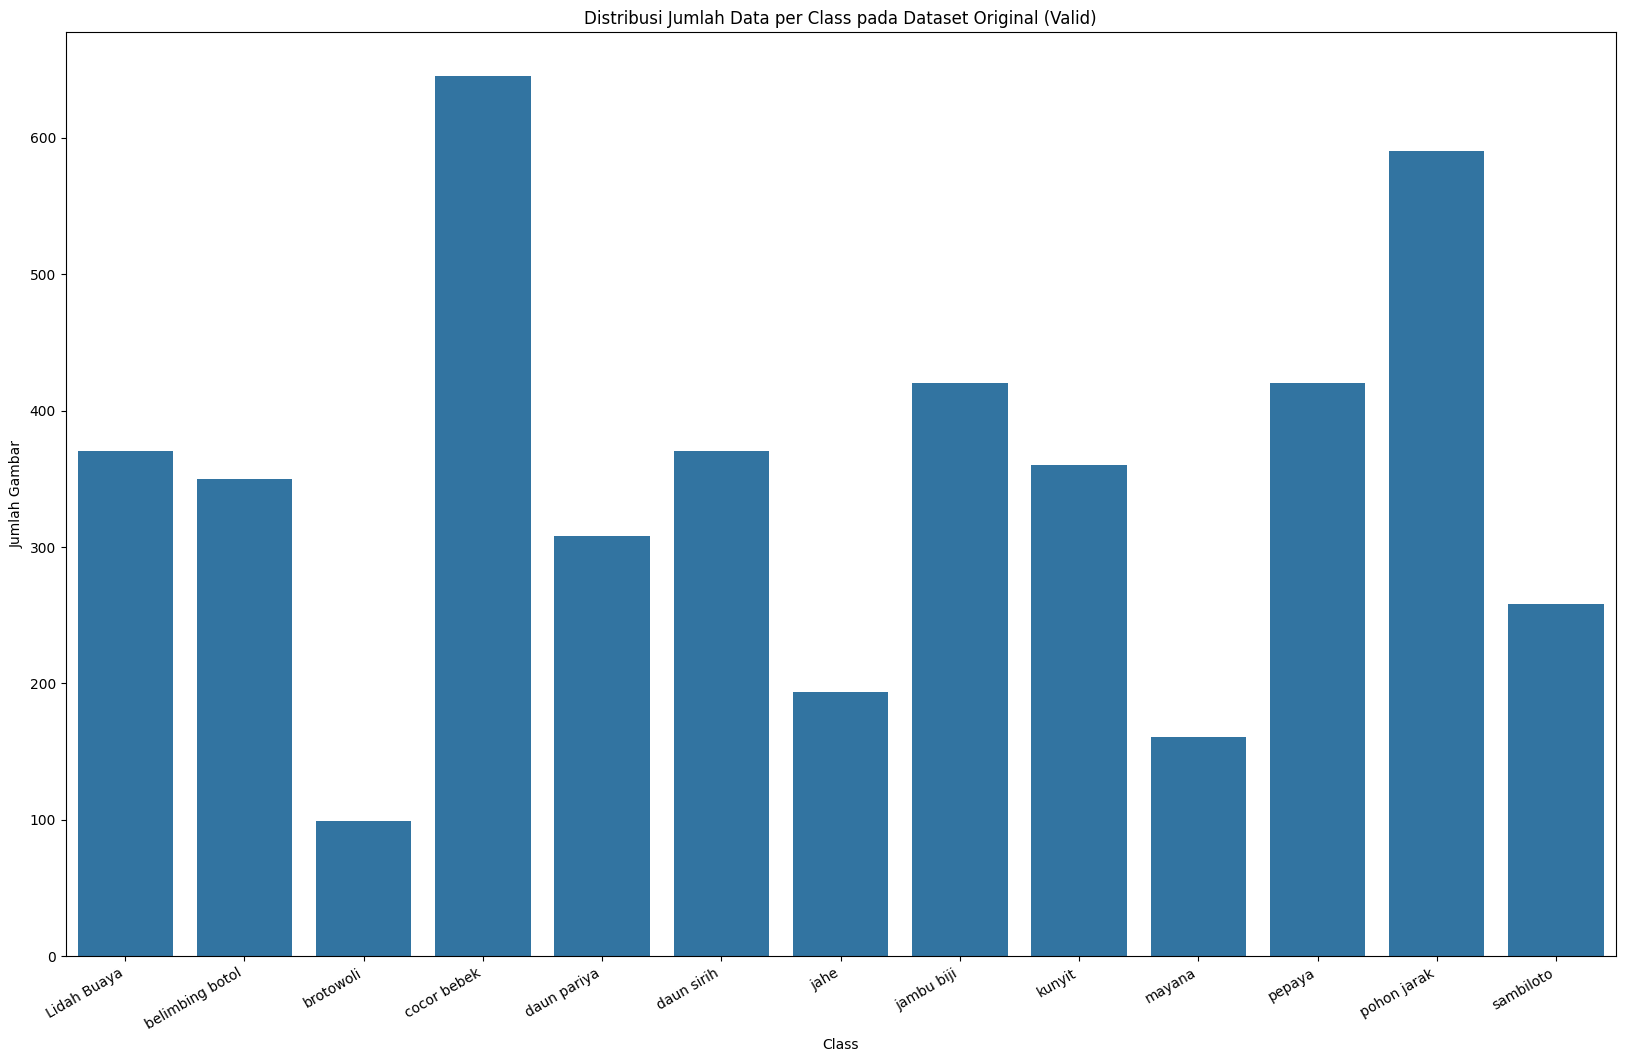

Jumlah data valid pada dataset original:
Lidah Buaya: 370 images
belimbing botol: 350 images
brotowoli: 99 images
cocor bebek: 645 images
daun pariya: 308 images
daun sirih: 370 images
jahe: 194 images
jambu biji: 420 images
kunyit: 360 images
mayana: 161 images
pepaya: 420 images
pohon jarak: 590 images
sambiloto: 258 images


In [4]:
# Distribusi jumlah data per kelas pada dataset valid (sebelum split)
ori_df = (
    clean_df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("Class")
    .reset_index(name="Count")
)

plt.figure(figsize=(20, 12))
sns.barplot(x="Class", y="Count", data=ori_df)
plt.title("Distribusi Jumlah Data per Class pada Dataset Original (Valid)")
plt.xlabel("Class")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=30, ha="right")
plt.show()

print("Jumlah data valid pada dataset original:")
for _, row in ori_df.iterrows():
    print(f"{row['Class']}: {row['Count']} images")

## 5. Ngeliat Langsung Visual Fotonya Pake Mata (Sample Plot)

Biar gampang, skrip ini ngambil se-random-ngambil 5 foto beda per kategori daun dari gudang `train_df`. Buat dipampang berjejer di layar jupyter ini.

Ini dipake ngelihat langsung tingkat kerumitan background daunnya (contoh: warnanya sama-sama gelap, potongan uratnya gimana). Si AI nanti bakal belajarin itu. Kalau pake mata manusia bingung mbedain Daun Sirsak sama Salam, AI-nya bakal lebih pusing! Kita pajang foto aslinya di sini biar yakin.

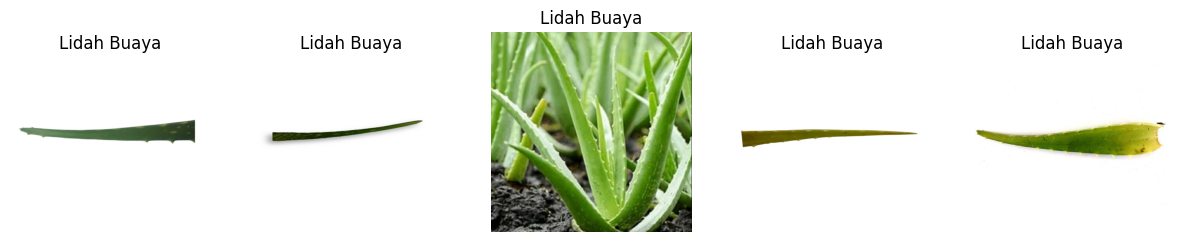

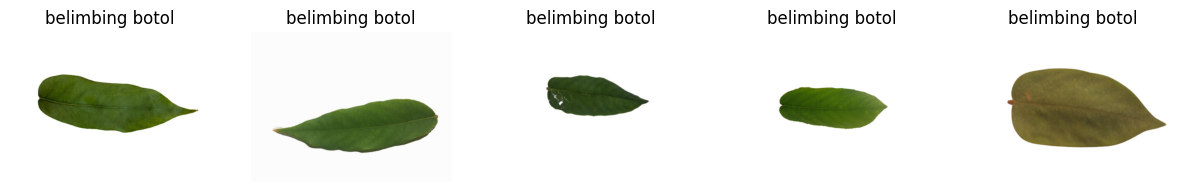

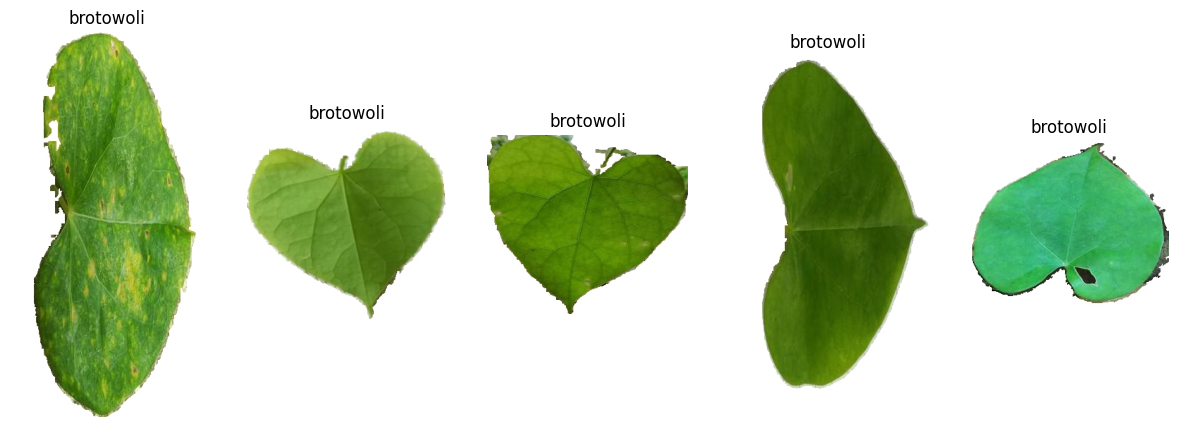

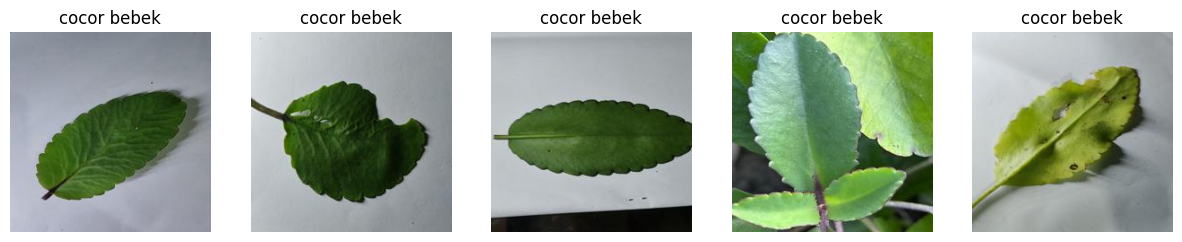

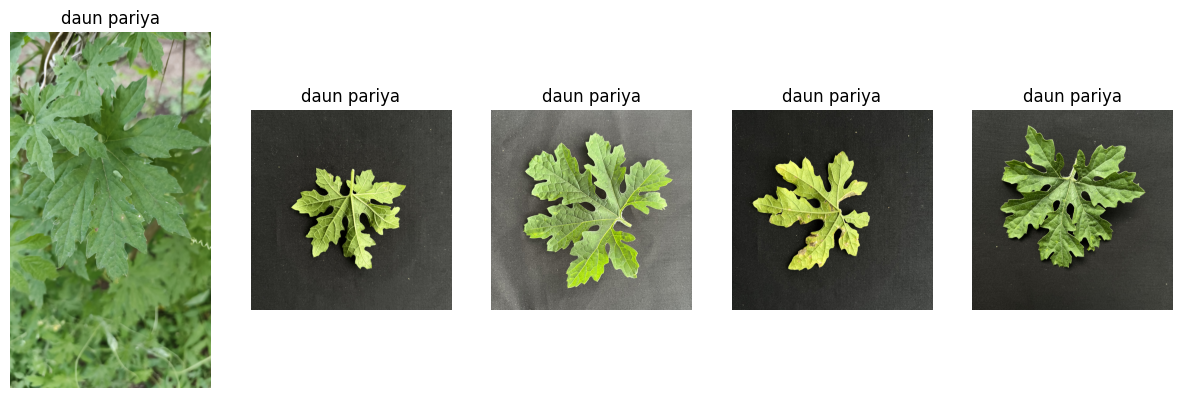

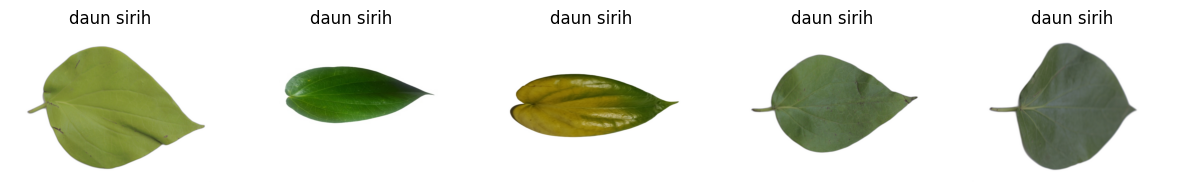

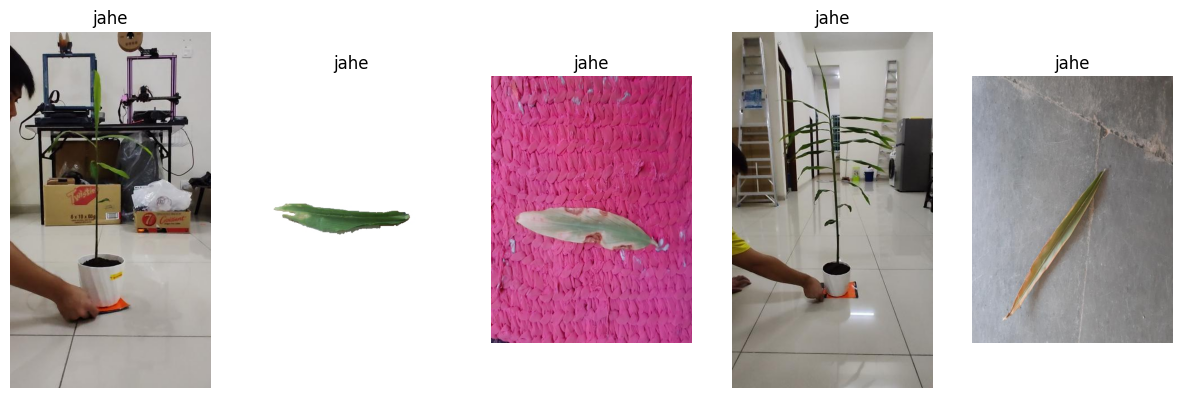

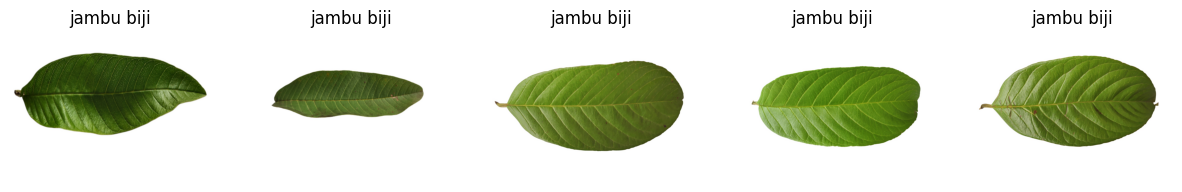

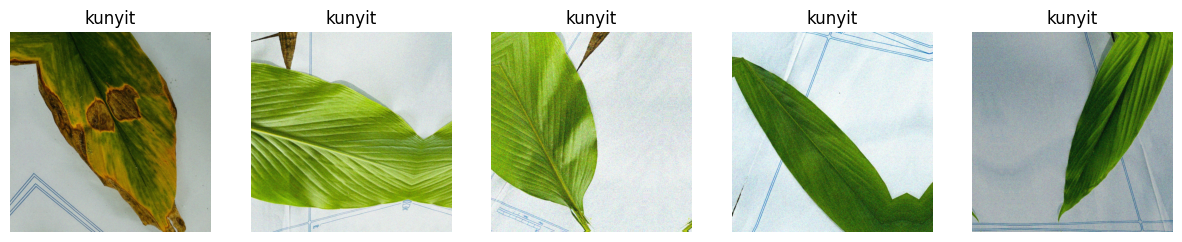

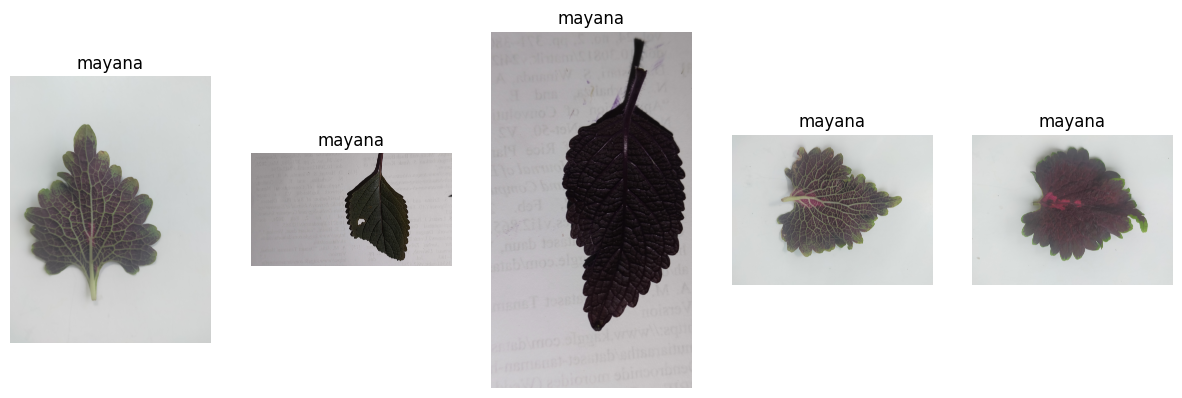

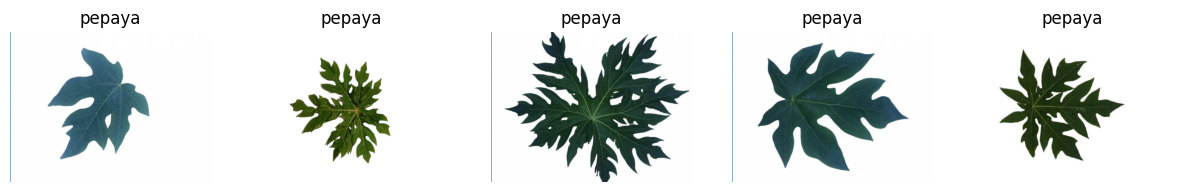

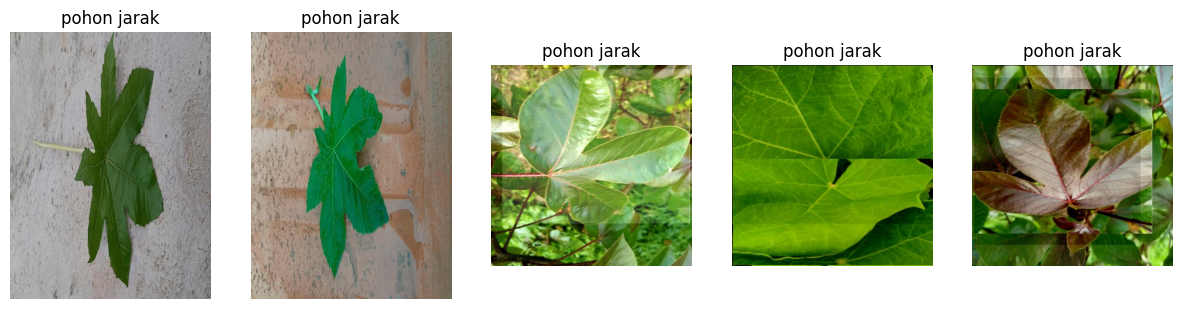

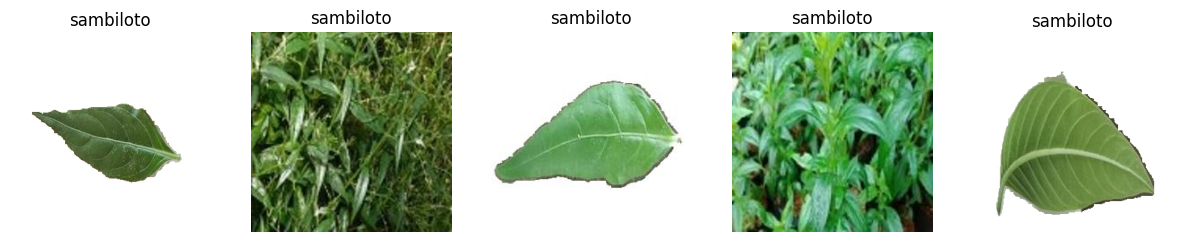

In [5]:
# Visualisasi beberapa gambar dari data train (tanpa folder split)
def plot_sample_images_from_df(df, class_name, max_samples=5):
    class_rows = df[df["label"] == class_name]
    num_samples = min(max_samples, len(class_rows))
    if num_samples == 0:
        print(f"Kelas '{class_name}' tidak memiliki gambar pada train set.")
        return

    sample_rows = class_rows.sample(n=num_samples, random_state=random_state)

    plt.figure(figsize=(15, 5))
    for i, (_, row) in enumerate(sample_rows.iterrows(), start=1):
        img = plt.imread(row["filepath"])
        plt.subplot(1, num_samples, i)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")
    plt.show()

for class_name in class_names:
    plot_sample_images_from_df(train_df, class_name)

## 6. Laporan Hasil Bagi Partisi Punya Siapa Aja

Grafik 3 panel berbaris (*Train | Validation | Test*) di bawah ini ngetes bener nggak kita udah bagi porsi `80:10:10` dengan waras tanpa merugikan satu jenis Daun pun. Ingat ya:

- **Train Set**: Buku soal teori dasar biar AI-nya kenal bener sama urat kemangi.
- **Validation Set**: Kisi-kisi nilai atau "tryout" sementara. Habis sekali ujian (1 epoch), dia koreksi kesalahan nebak (*Validation Loss*) dan benerin strateginya.
- **Test Set**: Kertas Soal Ujian Nasional (Kunci Jawaban Murni / Ujian Buta). Isinya gambar yang disembunyiin sejak awal (*unseen data*). Gunanya buat ngomongin dengan nyata, model ini aslinya pinter `90%` di lapangan atau dapet `80%` aja pas kerja nebak Daun dunia nyata!

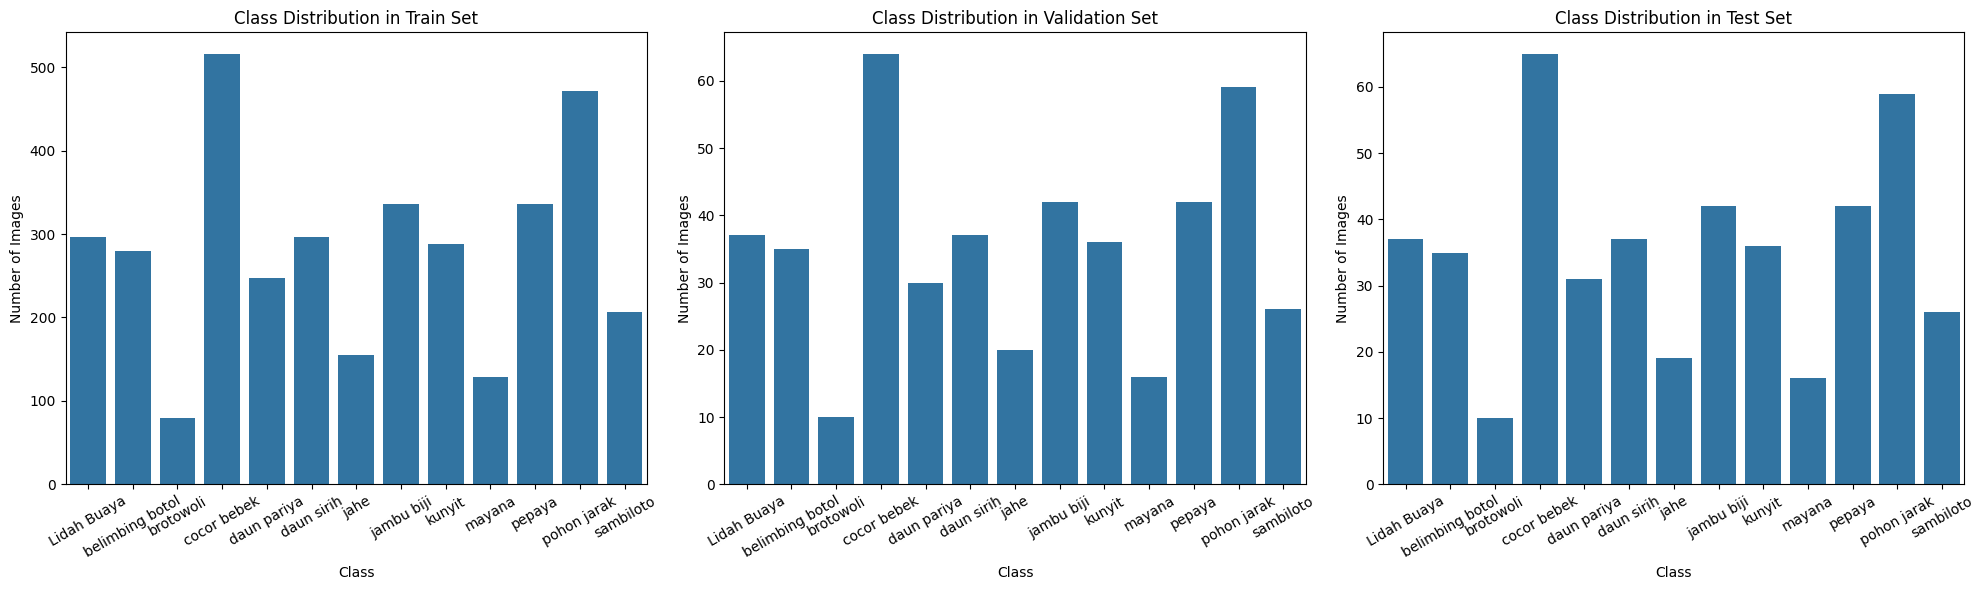

Class distribution in training set:
              Class  Count
0       Lidah Buaya    296
1   belimbing botol    280
2         brotowoli     79
3       cocor bebek    516
4       daun pariya    247
5        daun sirih    296
6              jahe    155
7        jambu biji    336
8            kunyit    288
9            mayana    129
10           pepaya    336
11      pohon jarak    472
12        sambiloto    206
Class distribution in validation set:
              Class  Count
0       Lidah Buaya     37
1   belimbing botol     35
2         brotowoli     10
3       cocor bebek     64
4       daun pariya     30
5        daun sirih     37
6              jahe     20
7        jambu biji     42
8            kunyit     36
9            mayana     16
10           pepaya     42
11      pohon jarak     59
12        sambiloto     26
Class distribution in test set:
              Class  Count
0       Lidah Buaya     37
1   belimbing botol     35
2         brotowoli     10
3       cocor bebek     65
4  

In [6]:
def get_class_distribution(df):
    return (
        df["label"]
        .value_counts()
        .sort_index()
        .rename_axis("Class")
        .reset_index(name="Count")
    )

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for idx, (df_split, name) in enumerate(
    zip([train_df, val_df, test_df], ["Train", "Validation", "Test"])
 ):
    df_plot = get_class_distribution(df_split)
    sns.barplot(x="Class", y="Count", data=df_plot, ax=axes[idx])
    axes[idx].set_title(f"Class Distribution in {name} Set")
    axes[idx].set_ylabel("Number of Images")
    axes[idx].set_xlabel("Class")
    axes[idx].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Class distribution in training set:")
train_distribution = get_class_distribution(train_df)
print(train_distribution)

print("Class distribution in validation set:")
val_distribution = get_class_distribution(val_df)
print(val_distribution)

print("Class distribution in test set:")
test_distribution = get_class_distribution(test_df)
print(test_distribution)

## 7. Bukti Berlapis Pembagian Dataset (Stacked Bar Chart)

Skrip *Python pandas/seaborn* ini nggabungin tiga warna di satu tempat `Train/Validation/Test` (*hue*). Ini lebih pantes buat discreening atau dilaporin dosen/atasan (karena simpel satu grafik batang tinggi tapi dipisah 3 tingkat). Lengkap sama angkanya langsung di atas batang warna itu sendiri biar nggak ribet nambah kalkulator.

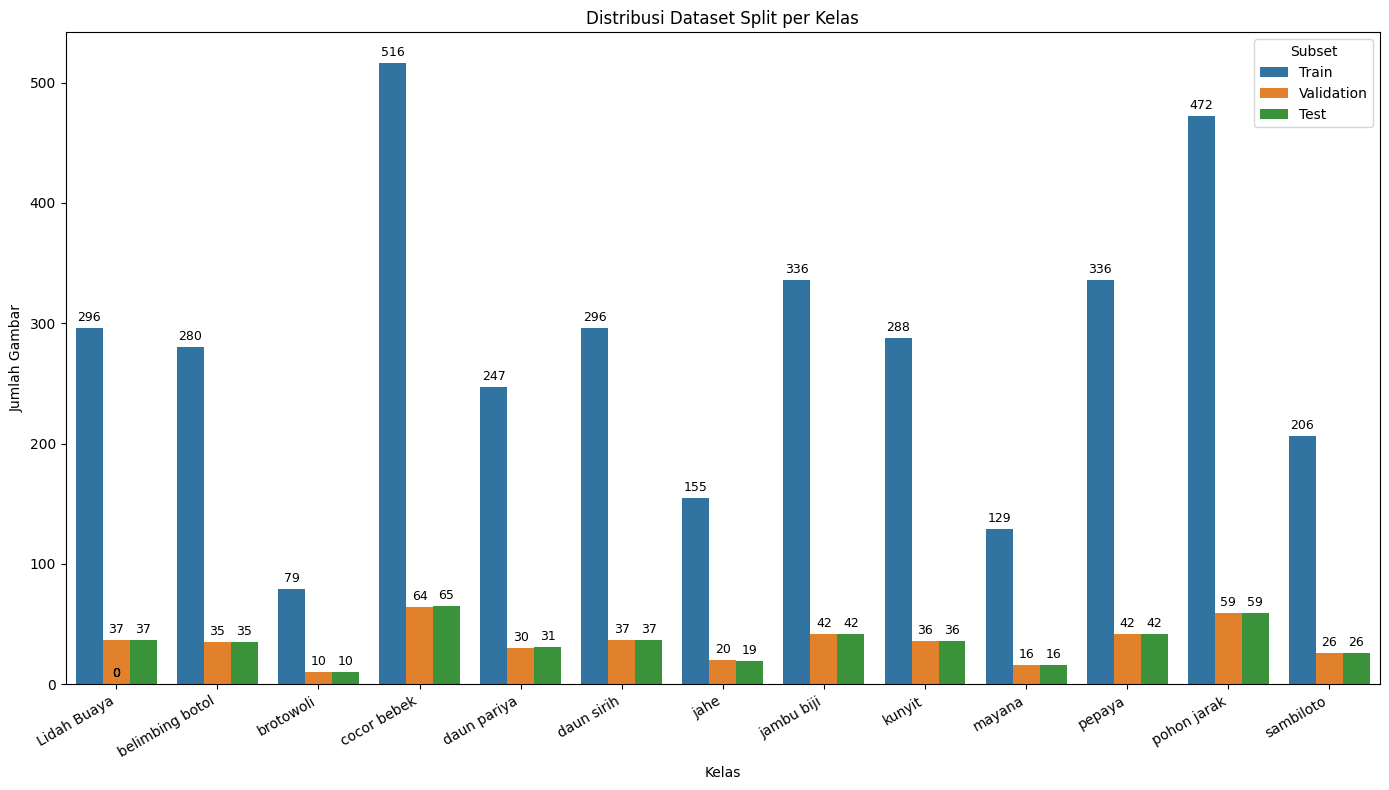

In [7]:
def plot_split_distribution(train_df, val_df, test_df):
    train_plot = get_class_distribution(train_df).assign(Subset="Train")
    val_plot = get_class_distribution(val_df).assign(Subset="Validation")
    test_plot = get_class_distribution(test_df).assign(Subset="Test")
    df = pd.concat([train_plot, val_plot, test_plot], ignore_index=True)

    plt.figure(figsize=(14, 8))
    ax = sns.barplot(x="Class", y="Count", hue="Subset", data=df)
    plt.title("Distribusi Dataset Split per Kelas")
    plt.xlabel("Kelas")
    plt.ylabel("Jumlah Gambar")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Subset")
    plt.tight_layout()

    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height):
            ax.annotate(
                f"{int(height)}",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=9,
                color="black",
                xytext=(0, 3),
                textcoords="offset points",
            )

    plt.show()

plot_split_distribution(train_df, val_df, test_df)

## 8. Persiapan Mesin Pemutar Foto Otomatis (Image Data Generator)

Nah ini, trik ngakalin file gambar dari *keras.preprocessing.image.ImageDataGenerator*!

Kalo model AI dipaksa ngapalin potret Daun Kumis Kucing miring 0 derajat terus, dia *bego* di dunia nyata waktu disodorin pake HP foto Daun Kumis Kucing miring 45 derajat doang. Kasus itu disebut **"Cuma Hafele" (Overfitting)**.

Makanya kita pake *Augmentation*:
- **Mutasi Gila-Gilaan (Training)**: Kalo lagi latian (train_datagen), kita masukin foto kita tadi ke Blender! Di puter (10 derajat), diputer-miringin (_shear/skew_), dideketin (_zoom_ 20%), dibolak-balik kaya cermin (horizontal flip), sampe layarnya digelapin/dicerahin. AI bakal ketipu dan belajar pola yang "real".
- **Realita Murni (Validation & Test)**: Nggak boleh disentuh aneh-aneh. Cuman diskala dari 0..255 jadi `0..1` RGB warnanya desimal. Biar ujiannya pake fakta aseli.

In [8]:
# **Augmentasi Data**
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=10,
    shear_range=0.2,
    zoom_range=0.2,
    brightness_range=[0.4, 1.5],
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1.0/255)

## 9. Siapin Generasi Antrian Batch (flow_from_dataframe)

Saatnya kita "pompa" foto-fotongan tadi pake *generator* (`flow_from_dataframe`) biar masuk GPU/RAM cepet! 

- Ngambil data secara *Batch* (*32 gambar* dipompa per *1* jalan/potongan).
- Semua ukuran gambar (baik `jpg/jpeg/png` atau ukuran `5 MegaPixel`) dipaksa jadi seukuran saku layar seragam `224 x 224 x 3` (piksel `Lebar x Tinggi x 3 Warna RGB`).
- Tiga antrian itu: `train_generator` (ini harus dikocok gambarnya /*shuffle* -- biar model nggak hafal urutan ABC), terus antrian `test/val` (ini diem aja, *shuffle=False*, buat diadu laporan sama *Confusion Matrix*-nya nanti bener enggak).

In [9]:
# Load dataset dengan augmentasi (tanpa membuat folder split)
batch_size = 32
target_size = (224, 224)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=target_size,
    batch_size=batch_size,
    class_mode="categorical",
    classes=class_names,
    shuffle=True,
 )

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=target_size,
    batch_size=batch_size,
    class_mode="categorical",
    classes=class_names,
    shuffle=False,
 )

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    target_size=target_size,
    batch_size=batch_size,
    class_mode="categorical",
    classes=class_names,
    shuffle=False,
 )

Found 3636 validated image filenames belonging to 13 classes.
Found 454 validated image filenames belonging to 13 classes.
Found 455 validated image filenames belonging to 13 classes.


## 10. Liat Efek Nyata Trik Pemutar Daun (*Training Augmentation Test*)

Emang bener daun kita tadi diacak-acak komputernya? Di sini fungsinya:
- Kita comot 1 potret daun orisinal!
- Lalu di-*looping* sambil dibedain (*_Mean Absolute Difference_* - warna/perbedaan) nyari foto paling ngaco tapi paling valid buat AI-nya dari 7 set putaran mutasi (*Zoom, Brightness, Combo Extreme*).
- Lalu dipasang jejer 2x4 di layar (*subplot*). Hasilnya harusnya keliatan beda sama yang asli, ada daun miring, kusam, mencong 30 derajat dll. Si Otak Komputer bakal disuruh nebak pola kombinasi susah beginian, **biar makin tangguh**!

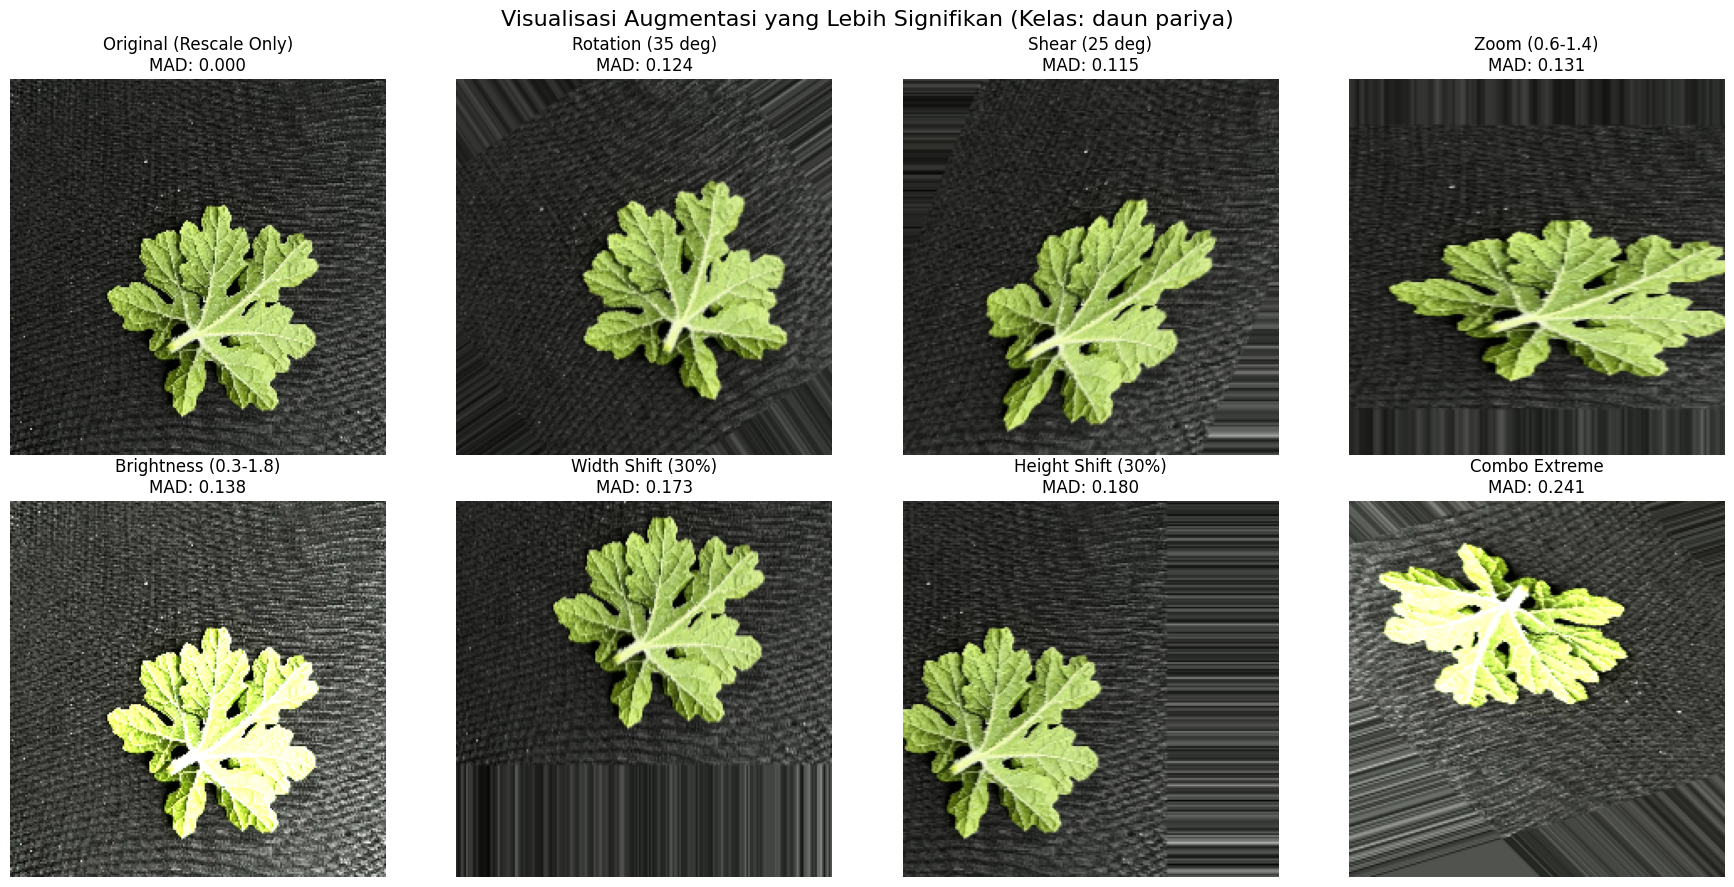

In [10]:
# Visualisasi berdasarkan jenis augmentasi (dibuat lebih kontras agar perbedaan terlihat jelas)
sample_row = train_df.sample(n=1, random_state=random_state).iloc[0]
sample_class = sample_row["label"]
img_path = sample_row["filepath"]

img = load_img(img_path, target_size=(224, 224))
x = img_to_array(img).astype(np.float32)
x_batch = np.expand_dims(x, axis=0)
x_ref = x / 255.0

def get_most_distinct_augmented_image(datagen, x_input, x_reference, n_trials=8):
    best_img = None
    best_score = -1.0

    for seed in range(random_state, random_state + n_trials):
        aug_iter = datagen.flow(x_input, batch_size=1, shuffle=False, seed=seed)
        aug_img = next(aug_iter)[0]
        # Mean Absolute Difference terhadap gambar asli sebagai ukuran perbedaan visual.
        score = np.mean(np.abs(aug_img - x_reference))
        if score > best_score:
            best_score = score
            best_img = aug_img

    return best_img, best_score

augmentations = {
    "Original (Rescale Only)": ImageDataGenerator(
        rescale=1.0/255
    ),
    "Rotation (35 deg)": ImageDataGenerator(
        rescale=1.0/255,
        rotation_range=35,
        fill_mode="nearest"
    ),
    "Shear (25 deg)": ImageDataGenerator(
        rescale=1.0/255,
        shear_range=25,
        fill_mode="nearest"
    ),
    "Zoom (0.6-1.4)": ImageDataGenerator(
        rescale=1.0/255,
        zoom_range=[0.6, 1.4],
        fill_mode="nearest"
    ),
    "Brightness (0.3-1.8)": ImageDataGenerator(
        rescale=1.0/255,
        brightness_range=[0.3, 1.8]
    ),
    "Width Shift (30%)": ImageDataGenerator(
        rescale=1.0/255,
        width_shift_range=0.3,
        fill_mode="nearest"
    ),
    "Height Shift (30%)": ImageDataGenerator(
        rescale=1.0/255,
        height_shift_range=0.3,
        fill_mode="nearest"
    ),
    "Combo Extreme": ImageDataGenerator(
        rescale=1.0/255,
        rotation_range=40,
        shear_range=25,
        zoom_range=[0.6, 1.4],
        width_shift_range=0.25,
        height_shift_range=0.25,
        brightness_range=[0.3, 1.8],
        horizontal_flip=True,
        vertical_flip=True,
        fill_mode="nearest"
    ),
}

plt.figure(figsize=(18, 9))
for i, (title, datagen) in enumerate(augmentations.items(), start=1):
    aug_img, diff_score = get_most_distinct_augmented_image(
        datagen,
        x_batch,
        x_ref,
        n_trials=8,
    )

    plt.subplot(2, 4, i)
    plt.title(f"{title}\nMAD: {diff_score:.3f}")
    plt.imshow(np.clip(aug_img, 0, 1))
    plt.axis("off")

plt.suptitle(
    f"Visualisasi Augmentasi yang Lebih Signifikan (Kelas: {sample_class})",
    fontsize=16,
 )
plt.tight_layout()
plt.show()

## 11. Arsitektur AI (MobileNetV2) yang Dibuat

Kalo mau jago, nyontek aja! Arsitektur model kita pake pondasi (metode *Transfer Learning*) hasil cetakan juara dunia, yakni **MobileNetV2** (ngambil bobot pinjeman dari *ImageNet*).

Garis Besarnya:
1. Porsi Muka Foto (224 x 224 x 3 warna)
2. Badan Model AI: MobileNetV2 (tapi otaknya kita hapus buat kita isikan model Daun-nya alias `include_top=False`)
3. Dikecilkan pake Layer `GlobalAveragePooling2D`
4. Disemantkan ke Otak/Layer utama `Dense (128 saraf) + ReLU` (Buat nge-hafal urat spesifik)
5. `Dropout (0.5)` (Sengaja nge-drop 50% saraf saat belajar, biar ga hafal urutan aja/Overfit)
6. Terminal Akhir (Output) pake `Dense (10 Saraf Hasil Kelas Daun)` pake penilai `Softmax`.

In [11]:
from tensorflow.keras.applications import MobileNetV2 
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Memuat arsitektur MobileNetV2 tanpa layer klasifikasi akhir (include_top=False)
base_model = MobileNetV2(
    weights='imagenet', 
    include_top=False, 
    input_shape=(224, 224, 3)
)

# Membekukan (freeze) layer pre-trained agar bobot aslinya tidak rusak saat awal proses training
base_model.trainable = False

# Membuat layer khusus untuk dataset 13 kelas daun TOGA kita
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)
predictions = Dense(13, activation="softmax")(x)

# Merangkai kembali keseluruhan model
model = Model(inputs=base_model.input, outputs=predictions)

model.summary()

I0000 00:00:1790669271.469755      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790669271.476230      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,423,629 (9.25 MB)

 Trainable params: 165,645 (647.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 12. Menyatukan Mesin AI-nya (Compile)

Pasangin nyawa ke Model `compile` yang udah kita rakit:
- **`loss`**: Nyawa buat ngekoreksi kesalahan (categorical_crossentropy). Kalau salah tebak, misalnya dia kira Sirsak padahal Daun Pandan 80%, skor ruginya dicatat (*Probabilitas Matriks*) nunggu 0..1.
- **`optimizer`**: Si Pengatur Belajarnya pake **ADAM** (*Adaptive Moment Estimation*), sebuah *"backpropagation"* jenius dari Komputer buat nyetel balik *Learning Rate* `0.001` setiap putaran `Epoch` tanpa kelolosan nebak (Cepet dan stabil jalannya).
- **`metrics`**: Pengen keluar laporan `% Akurasi` ketimbang hitungan `Loss` doang.

In [12]:
# **Compile Model**
model.compile(
    loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy']
)

## 13. Waktunya Ngelatih Si AI (Training Model) + Early Stop

Pas kode `model.fit()` jalan, ini yang kejadian:
- Dia diumpanin ribuan foto daun dari Generator (*batch 32*), diulangi terus sampe 50 ronde (*epochs*).
- Harusnya sih, *Validation Accuracy* (tingkat kebenaran hasil latih) makin nanjak dari 1 ke 50 ronde itu.
- **Early Stopping**: Kita pasangin *Rem Darurat* (_patience=5_). Kenapa? Kalau AI nebaknya tiba-tiba jadi *"halu" / Overfit* (hafal buta gambar tapi malah bego pas dikasih ujian Validation) selama 5 ronde berturut-turut, sistem nge-stop programnya seketika (mungkin stop di Epoch ke 23)! Dia otomatis nyimpen isi otak yang paling bagus sebelum hancur.
- Semua raport nilainya disimpen di variabel (`history`).

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

# **Inisialisasi Early Stopping**
# Akan menghentikan training jika val_loss tidak membaik selama 5 epoch, 
# dan otomatis mengembalikan bobot model ke versi terbaik.
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# **Training Model**
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=50,
    validation_data=val_generator,
    validation_steps=len(val_generator),
    callbacks=[early_stop]
)

Epoch 1/50


2026-09-29 08:08:18.486059: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-29 08:08:18.622864: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1790669301.653015     131 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 82/114 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.5245 - loss: 1.5292

2026-09-29 08:10:05.900550: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-29 08:10:06.037635: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5852 - loss: 1.3428

2026-09-29 08:11:10.867592: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-29 08:11:11.005966: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-29 08:11:11.142530: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-29 08:11:11.279182: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


114/114 ━━━━━━━━━━━━━━━━━━━━ 197s 2s/step - accuracy: 0.7627 - loss: 0.7945 - val_accuracy: 0.9427 - val_loss: 0.1856
Epoch 2/50
114/114 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.9202 - loss: 0.2693 - val_accuracy: 0.9714 - val_loss: 0.1071
Epoch 3/50
114/114 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.9455 - loss: 0.1798 - val_accuracy: 0.9736 - val_loss: 0.0956
Epoch 4/50
114/114 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9560 - loss: 0.1413 - val_accuracy: 0.9758 - val_loss: 0.0681
Epoch 5/50
114/114 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9604 - loss: 0.1281 - val_accuracy: 0.9736 - val_loss: 0.0687
Epoch 6/50
114/114 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9703 - loss: 0.1069 - val_accuracy: 0.9846 - val_loss: 0.0690
Epoch 7/50
114/114 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9755 - loss: 0.0769 - val_accuracy: 0.9780 - val_loss: 0.0765
Epoch 8/50
114/114 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9752 - loss: 0.0781 - val_accuracy: 0.978

## 14. Tes Keakuratan Kepintarannya (Evaluasi)

Waktunya nyoba alat `model.evaluate()`. Nah ini beneran UJIAN NASIONAL-nya model si MobileNetV2!

Si Generator Soal Ujian (`test_generator`) ngeluarin foto `10%` dari awal yang sama *sekali sengaja nggak pernah di-lihatin ke Model AI* pas lagi latih-latih di 50 putaran tadi. Kalo keluar *Test Accuracy* (Murni) di 100.0% berarti Robot AI pemilah Daun kita nilainya Sempurna!

In [14]:
# **Evaluasi Model**
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 987ms/step - accuracy: 0.9767 - loss: 0.0957

2026-09-29 08:47:25.364967: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-29 08:47:25.501516: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


15/15 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.9824 - loss: 0.0636 
Test Accuracy: 98.24%


## 15. Ekspor Otak Pintarnya Jadi File (Save Model MobileNetV2)

Buat nebak daun TOGA pakai web atau HP, Komputer kan nggak perlu ngelatih lagi dan *ngabisin* sejam 50 rondenya terus ya nggak? 
Langsung suntik alias nge-_save_ bobot *pattern recognition* dari si 128 sarafnya (`model.save()`) pakai format paling pas:
- **`daun.h5`**: Format HDF5 standar jaman baheula, paling kokoh disambung ke web pake API Flask Python.
- **`daun.keras`**: Format kompres super baru punya Keras v3. Ngga makan tempat di Hardisk.
- **`daun_savedmodel`**: Isi banyak map, tapi *TensorFlow Serving / Tflite / JavaScript* bakalan gampang banget melahap hasil AI aseli dari model (*Produksi Skala Web/HP yang mantep*).

In [15]:
# Simpan model
model.save("daun.keras")
model.save("daun.h5")

try:
    model.export("daun_savedmodel")
except AttributeError:
    tf.saved_model.save(model, "daun_savedmodel")

print("Model tersimpan: daun.keras, daun.h5, daun_savedmodel/")

INFO:tensorflow:Assets written to: daun_savedmodel/assets


INFO:tensorflow:Assets written to: daun_savedmodel/assets


Saved artifact at 'daun_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 13), dtype=tf.float32, name=None)
Captures:
  136348918552848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030982736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030990800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030990416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030985616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030990992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030989264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030991568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030991184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136346030989456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13634603098772

## 16. Masukin *Meteran* SkLearn (Ngecek Keadilan)

Akurasi *e.g. 92.5%* di rapor? Emang yakin AI-nya mbedain Serai sama Kemangi adil? Siapa tau dia asbun asal nebak *"Ah ini Pandan semua!"* dan pas kebetulan ujian emang isinya Pandan 90%!

Di sinilah letak alat tes kepintaran per-daun *"Bias Test"* unjuk fungsi (`classification_report` dan tabel warna-warni kotak silang `confusion_matrix`).  Sistem AI bakal disuruh nebak satu-satu tanpa ngumpet. Terus dijodohkan dengan tabel salah nebak (Warna Positif = Bener | Warna Negatif/Ngeselin = Salah). Seaborn bakal bikinin petanya (*Jadi Heatmap*).

In [16]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

## 17. Grafik Laju Belajar (Training Curve MobileNetV2)

Raport grafiknya Jaringan saraf (Deep Learning) kaya kurva saham (*history*). 
- *Akurasi* (garis nanjak itu artinya seneng).
- *Eror / Loss* (Hutang nilai, grafik turun menukik itu sukses! Berarti salah belajarnya minimal).

Logika nyambungnya sih pas liat garis biru (`Latihan`) dan kuning (`Tryout/Validation`) ngga terpisahkan. Kalo si biru (latihan) 100%, tapi garis kuningnya patah arah nggak nyambung di Ronde *Epoch 40*, astaga si model pasti *Overfitting* (Kebanyakan hafal rumus, tapi bego di luar kepala ngerjain soal test).
Kalo garis sehidup-sematik itu bagus alias Emas (`Good Fit / Generalization / Siap Pakar Daun Lulus`).

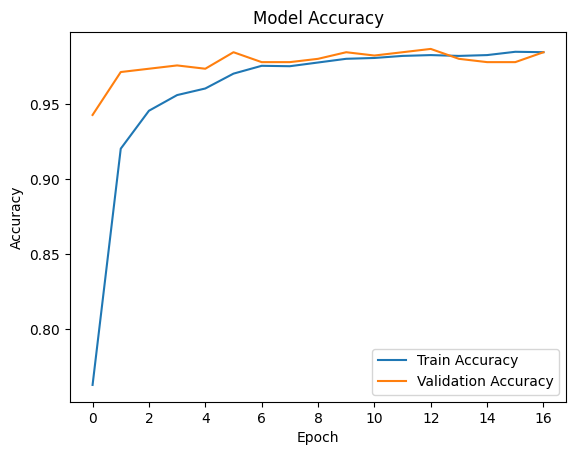

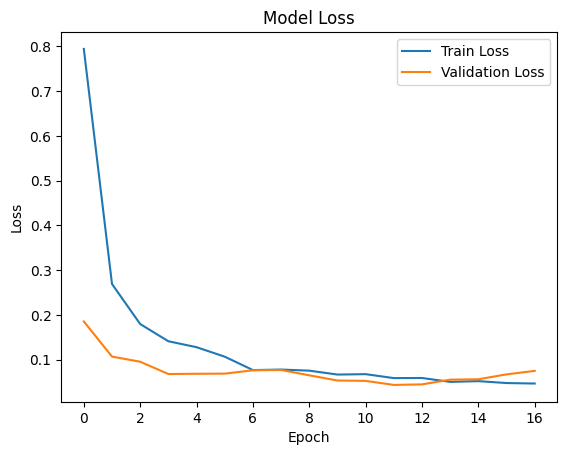

In [17]:
# Plot Akurasi
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## 18. Laporan Tabel Nebak Daun: Bener vs Salah Bikin Baper (Mata Telanjang / Confusion Matrix)

Di Tabel `10x10` (*MobileNetV2 Negejar Kelas Daun Pake Heatmap*):
1. `model.predict` jalan keras ngerjain Ribuan Foto `(Test/Unseen)`.
2. Hasil Jawabannya `y_pred` dijodohin sama Jawaban Rahasia aslinya `true_classes`.
3. Nah, Kalo nebaknya Jahe ternyata bener Jahe, angkanya (*True Positive*) melukluk tebel-nanjak ke sumbu miring Diagonal sempurna `\`. 
4. Di luar Miring itu: *False Positive / Negative* ... Waduh, contoh Daun Kemangi tapi dijawab Salam 15x. AI kamu bego, perlu diliatin angkanya merah di mana ntar ketahuan dari laporan *Scikit-Learn* (`classification_report` = F1-Score detail per tanaman).

15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 916ms/step


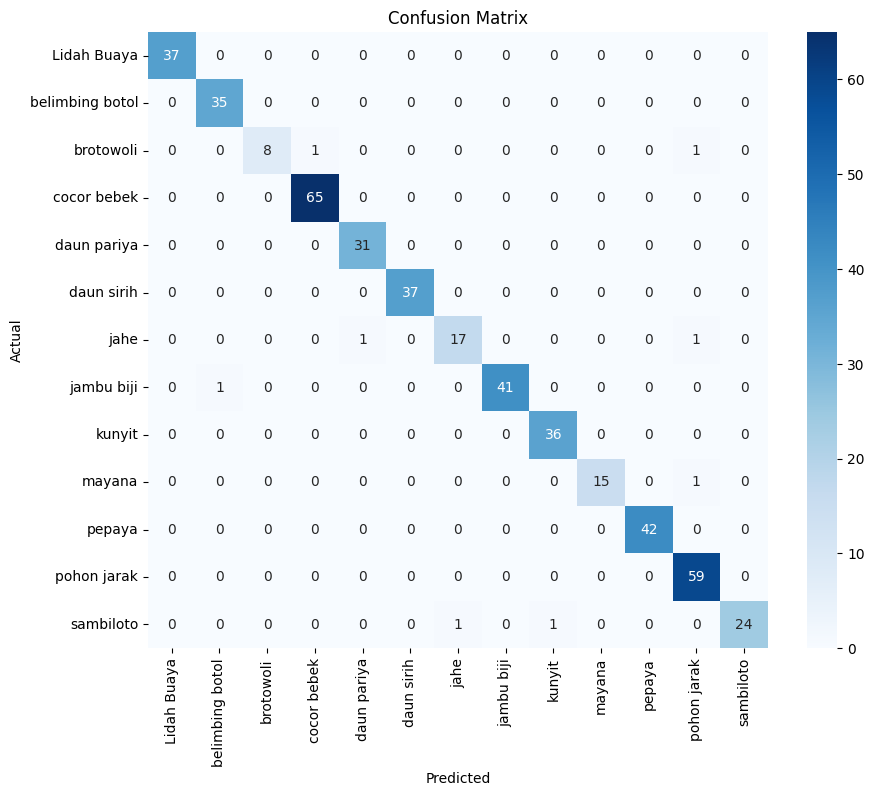


Classification Report:
                 precision    recall  f1-score   support

    Lidah Buaya       1.00      1.00      1.00        37
belimbing botol       0.97      1.00      0.99        35
      brotowoli       1.00      0.80      0.89        10
    cocor bebek       0.98      1.00      0.99        65
    daun pariya       0.97      1.00      0.98        31
     daun sirih       1.00      1.00      1.00        37
           jahe       0.94      0.89      0.92        19
     jambu biji       1.00      0.98      0.99        42
         kunyit       0.97      1.00      0.99        36
         mayana       1.00      0.94      0.97        16
         pepaya       1.00      1.00      1.00        42
    pohon jarak       0.95      1.00      0.98        59
      sambiloto       1.00      0.92      0.96        26

       accuracy                           0.98       455
      macro avg       0.98      0.96      0.97       455
   weighted avg       0.98      0.98      0.98       455



In [18]:
import numpy as np

# Prediksi semua data di test_generator
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)

# Ambil label asli
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Confusion Matrix
conf_matrix = confusion_matrix(true_classes, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(true_classes, y_pred, target_names=class_labels))

## 19. Ngetes AI-nya Nebak 5 Foto Sembarangan (Visual Test)

Cuma liat grafik angka-angkanya aja kurang asik, kita harus tau gimana wujud AI ini *"nebak secara kasat mata"* kan?

Kita ngacak (*module `random`*) lima `(5)` lembar potret rahasia pakenya `test_generator`. Foto-foto kusam atau tajem (*image pixel RGB*) ini dipaparkan langsung di layar. Di jeroan AI `.predict`, mesin MobileNetV2 bakal berjerih payah cari persentase tergede (`np.argmax`) buat dikawinin ke **Label Asli : Jahe** dan **Label Tebakan AI : Jahe**. Kalo emang jawabannya *works* tulisan Sirih itu sama-sama cucok!

2026-09-29 08:48:16.613974: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-29 08:48:16.750387: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step


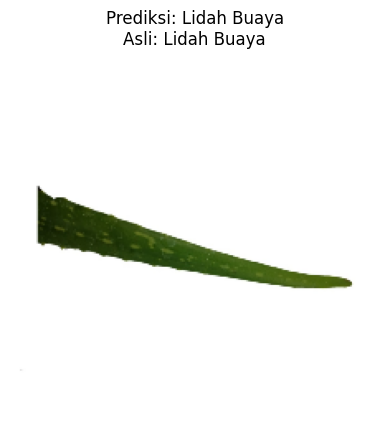

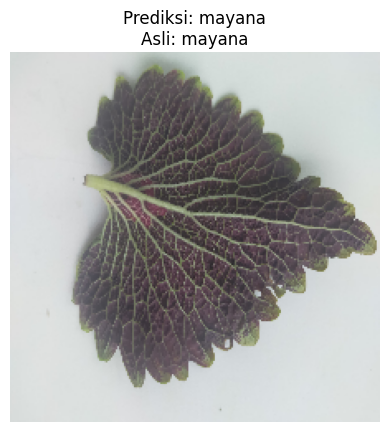

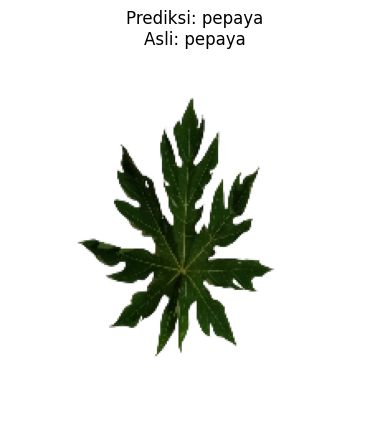

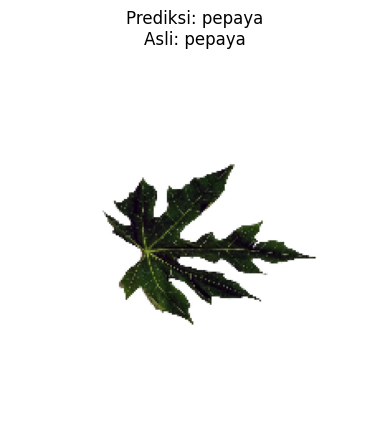

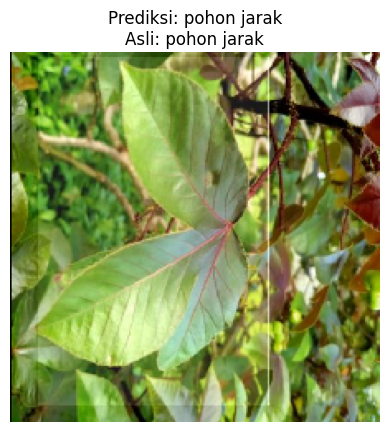

In [19]:
import random

# Ambil 5 sampel acak dari test_generator
sample_indices = random.sample(range(len(test_generator.filenames)), 5)
sample_files = [test_generator.filenames[i] for i in sample_indices]
sample_images, sample_labels = [], []

# Load batch of images and labels
for _ in range(len(test_generator)):
    img_batch, label_batch = next(test_generator)
    for img, label in zip(img_batch, label_batch):
        sample_images.append(img)
        sample_labels.append(label)

# Select the samples based on the random indices
sample_images = [sample_images[i] for i in sample_indices]
sample_labels = [sample_labels[i] for i in sample_indices]

# Prediksi sampel
sample_images = np.array(sample_images)
predictions = model.predict(sample_images)
predicted_classes = np.argmax(predictions, axis=1)

# Tampilkan hasil prediksi
for i, img in enumerate(sample_images):
    plt.imshow(img)
    plt.title(f"Prediksi: {class_labels[predicted_classes[i]]}\nAsli: {class_labels[np.argmax(sample_labels[i])]}")
    plt.axis('off')
    plt.show()


## 20. Ngitung Rumus Kepintaran (TP, TN, FP, FN / Metrik Manual Klasifikasi)

Di bagian terakhir (sel *Jupyter* ini), tabel penjabaran detil tiap-tiap daun bakal diluapin (enak dipake lapor ke Dosen/Tesis Akademik). Dia ngambil matriks *Conf_matrix* trus dicek pakai *Loop*:
- Diambil irisan garis benernya (*True Positive* / Nebak bener Pandan = Pandan).
- Ngecek jajaran miring garis keledai menyamping (`False Negative` = Aslinya Pandan eh AI nebak Kumis Kucing).
- Nyata nggabret ke atas (`False Positive` = Aslinya Sirsak eh AI nebak dia Pandan).
- Semuanya ditampilin pake *Matplotlib Table* asik `Precision`, `Recall`, `F1-Score` hitung manual matematisnya. Hasil jepretan ini di-croschek lagi sama kalkulator asli punya `Scikit-Learn`. Kalo nilainya cocok banget, Model Pakar AI Daun TOGA MobileNetV2-mu berkelas *Top Dunia/Lulus!*

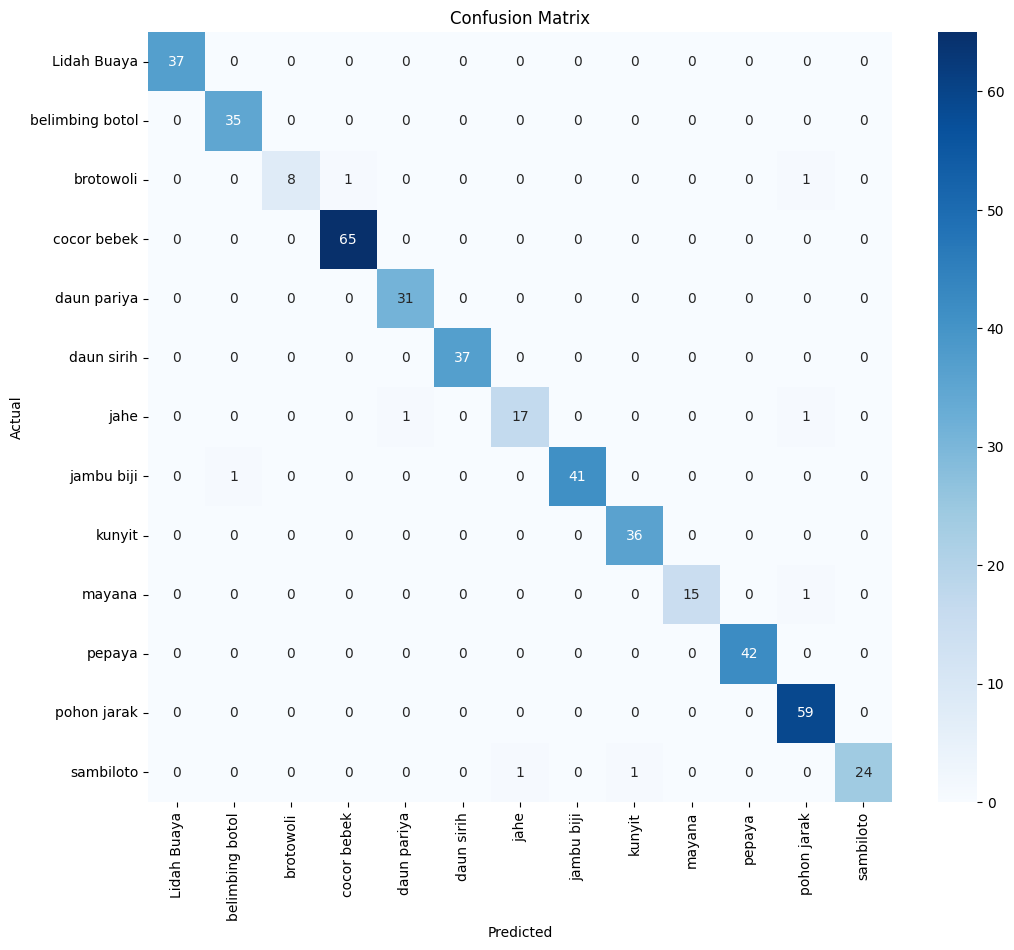

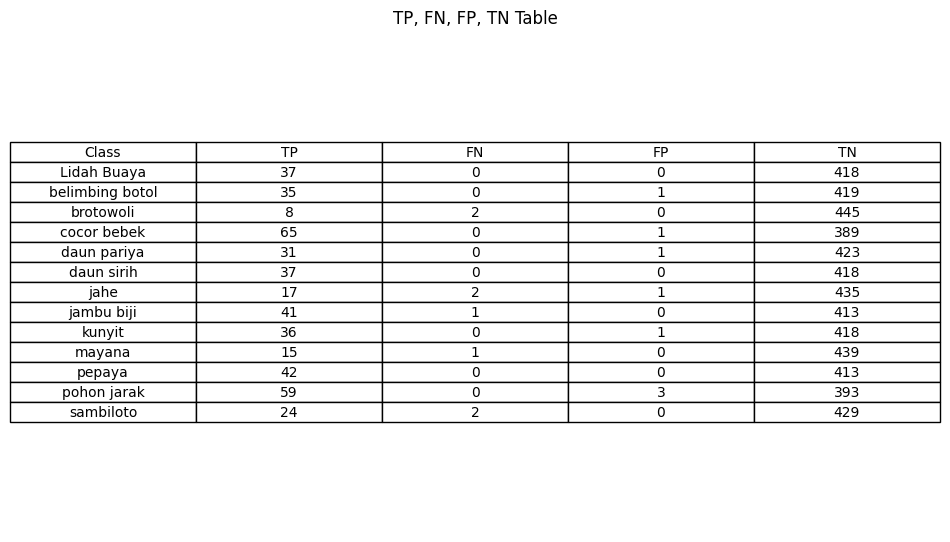


TP, FN, FP, TN for each class:
Lidah Buaya: TP=37, FN=0, FP=0, TN=418
belimbing botol: TP=35, FN=0, FP=1, TN=419
brotowoli: TP=8, FN=2, FP=0, TN=445
cocor bebek: TP=65, FN=0, FP=1, TN=389
daun pariya: TP=31, FN=0, FP=1, TN=423
daun sirih: TP=37, FN=0, FP=0, TN=418
jahe: TP=17, FN=2, FP=1, TN=435
jambu biji: TP=41, FN=1, FP=0, TN=413
kunyit: TP=36, FN=0, FP=1, TN=418
mayana: TP=15, FN=1, FP=0, TN=439
pepaya: TP=42, FN=0, FP=0, TN=413
pohon jarak: TP=59, FN=0, FP=3, TN=393
sambiloto: TP=24, FN=2, FP=0, TN=429


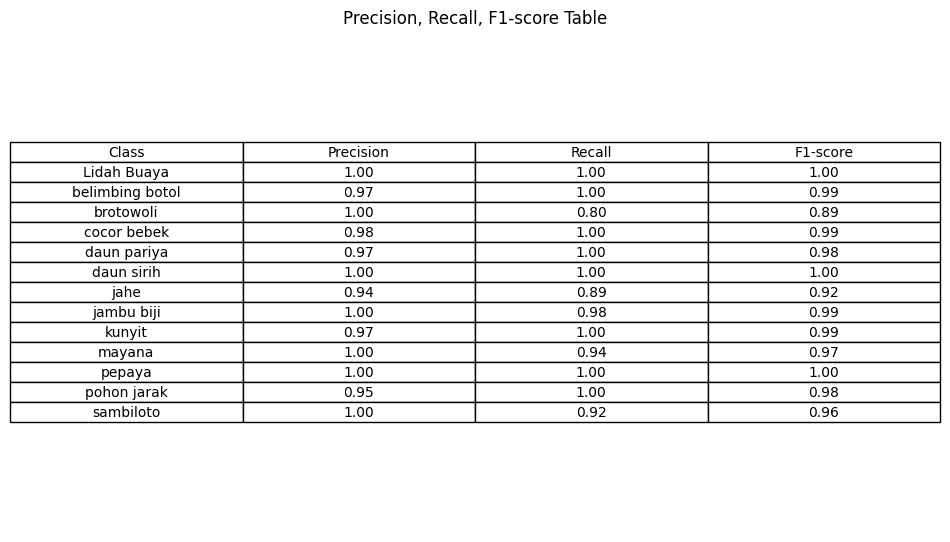


Classification Report (Sklearn):
                 precision    recall  f1-score   support

    Lidah Buaya       1.00      1.00      1.00        37
belimbing botol       0.97      1.00      0.99        35
      brotowoli       1.00      0.80      0.89        10
    cocor bebek       0.98      1.00      0.99        65
    daun pariya       0.97      1.00      0.98        31
     daun sirih       1.00      1.00      1.00        37
           jahe       0.94      0.89      0.92        19
     jambu biji       1.00      0.98      0.99        42
         kunyit       0.97      1.00      0.99        36
         mayana       1.00      0.94      0.97        16
         pepaya       1.00      1.00      1.00        42
    pohon jarak       0.95      1.00      0.98        59
      sambiloto       1.00      0.92      0.96        26

       accuracy                           0.98       455
      macro avg       0.98      0.96      0.97       455
   weighted avg       0.98      0.98      0.98      

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# # Prediksi semua data di test_generator
# Y_pred = model.predict(test_generator)
# y_pred = np.argmax(Y_pred, axis=1)

# # Ambil label asli
# true_classes = test_generator.classes
# class_labels = list(test_generator.class_indices.keys())

# 1. **Tampilkan Confusion Matrix**
conf_matrix = confusion_matrix(true_classes, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# 2. **Hitung TP, FN, FP, TN untuk setiap kelas**
num_classes = len(class_labels)
total_samples = np.sum(conf_matrix)

TP_list, FN_list, FP_list, TN_list = [], [], [], []

for i in range(num_classes):
    TP = conf_matrix[i, i]  # True Positive
    FN = np.sum(conf_matrix[i, :]) - TP  # False Negative
    FP = np.sum(conf_matrix[:, i]) - TP  # False Positive
    TN = total_samples - (TP + FP + FN)  # True Negative

    TP_list.append(TP)
    FN_list.append(FN)
    FP_list.append(FP)
    TN_list.append(TN)

# 3. **Visualisasi TP, FN, FP, TN dalam tabel**
fig, ax = plt.subplots(figsize=(10, num_classes * 0.5))
ax.axis('tight')
ax.axis('off')
table_data = [['Class', 'TP', 'FN', 'FP', 'TN']] + [[class_labels[i], TP_list[i], FN_list[i], FP_list[i], TN_list[i]] for i in range(num_classes)]
table = ax.table(cellText=table_data, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.2)
plt.title('TP, FN, FP, TN Table')
plt.show()

print("\nTP, FN, FP, TN for each class:")
for i in range(num_classes):
    print(f"{class_labels[i]}: TP={TP_list[i]}, FN={FN_list[i]}, FP={FP_list[i]}, TN={TN_list[i]}")


# 4. **Hitung Precision, Recall, F1-score secara manual**
precision_list = [TP / (TP + FP) if (TP + FP) != 0 else 0 for TP, FP in zip(TP_list, FP_list)]
recall_list = [TP / (TP + FN) if (TP + FN) != 0 else 0 for TP, FN in zip(TP_list, FN_list)]
f1_score_list = [2 * (p * r) / (p + r) if (p + r) != 0 else 0 for p, r in zip(precision_list, recall_list)]

# **Visualisasi Precision, Recall, F1-score**
fig, ax = plt.subplots(figsize=(10, num_classes * 0.5))
ax.axis('tight')
ax.axis('off')
metrics_data = [['Class', 'Precision', 'Recall', 'F1-score']] + [[class_labels[i], f"{precision_list[i]:.2f}", f"{recall_list[i]:.2f}", f"{f1_score_list[i]:.2f}"] for i in range(num_classes)]
table = ax.table(cellText=metrics_data, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.2)
plt.title('Precision, Recall, F1-score Table')
plt.show()

# 5. **Bandingkan dengan Classification Report dari Scikit-learn**
print("\nClassification Report (Sklearn):")
print(classification_report(true_classes, y_pred, target_names=class_labels))


In [21]:
!zip -r herbal.zip /kaggle/working

  adding: kaggle/working/ (stored 0%)
  adding: kaggle/working/.virtual_documents/ (stored 0%)
  adding: kaggle/working/.virtual_documents/__notebook_source__.ipynb (deflated 69%)
  adding: kaggle/working/daun.keras (deflated 12%)
  adding: kaggle/working/daun.h5 (deflated 12%)
  adding: kaggle/working/daun_savedmodel/ (stored 0%)
  adding: kaggle/working/daun_savedmodel/fingerprint.pb (stored 0%)
  adding: kaggle/working/daun_savedmodel/variables/ (stored 0%)
  adding: kaggle/working/daun_savedmodel/variables/variables.index (deflated 77%)
  adding: kaggle/working/daun_savedmodel/variables/variables.data-00000-of-00001 (deflated 7%)
  adding: kaggle/working/daun_savedmodel/assets/ (stored 0%)
  adding: kaggle/working/daun_savedmodel/saved_model.pb (deflated 90%)


In [22]:
from IPython.display import FileLink
FileLink(r'herbal.zip')

/kaggle/working/herbal.zip